# What has been the fate of 2020 young/old boreal forests over 5 years

+ bring AGBD trends and the kendall's tau analysis together with C accumulation to estimate the fate of C accumuation trajectories in the early 2020s
+ this is interesting b/c it gets at what impact fires are having on forests that otherwise might be accumulating C at fast rates.
+ it explains a result of the intensification of the fire cycle.

#### Literature
```bash
Yang, H., Ciais, P., Frappart, F. et al. Global increase in biomass carbon stock dominated by growth of northern young forests over past decade. Nat. Geosci. 16, 886–892 (2023). https://doi.org/10.1038/s41561-023-01274-4

Pulliainen et al 2024. Increase in gross primary production of boreal forests balanced out by increase in ecosystem respiration  https://doi.org/10.1016/j.rse.2024.114376

Burrell, Arden L., Sol Cooperdock, Stefano Potter, Logan T. Berner, Robert Hember, Matthew J. Macander, Xanthe J. Walker, et al. 2024. “ The Predictability of Near-Term Forest Biomass Change in Boreal North America.” Ecosphere 15(1): e4737. https://doi.org/10.1002/ecs2.4737

Chen, H.Y.H., Luo, Y., Reich, P.B., Searle, E.B. and Biswas, S.R. (2016), Climate change-associated trends in net biomass change are age dependent in western boreal forests of Canada. Ecol Lett, 19: 1150-1158. https://doi.org/10.1111/ele.12653  

Schepaschenko, D., Moltchanova, E., Fedorov, S. et al. Russian forest sequesters substantially more carbon than previously reported. Sci Rep 11, 12825 (2021). https://doi.org/10.1038/s41598-021-92152-9  

Wu & Hisano 2024. Spatial variation in boreal forest responses to global environmental change in western Canada. https://doi.org/10.1016/j.agrformet.2024.110140  

Europe 2019 drought: https://doi.org/10.5194/nhess-22-2201-2022
```

### To do this at scale:  
1. DPS years 2019-2024 from `full_run_niter30_multiyear_atl08v6`
2. Get total AGB stock annually for boreal: 2016-2025
   + `tile_stats_v3.1_multiyear.ipynb`
   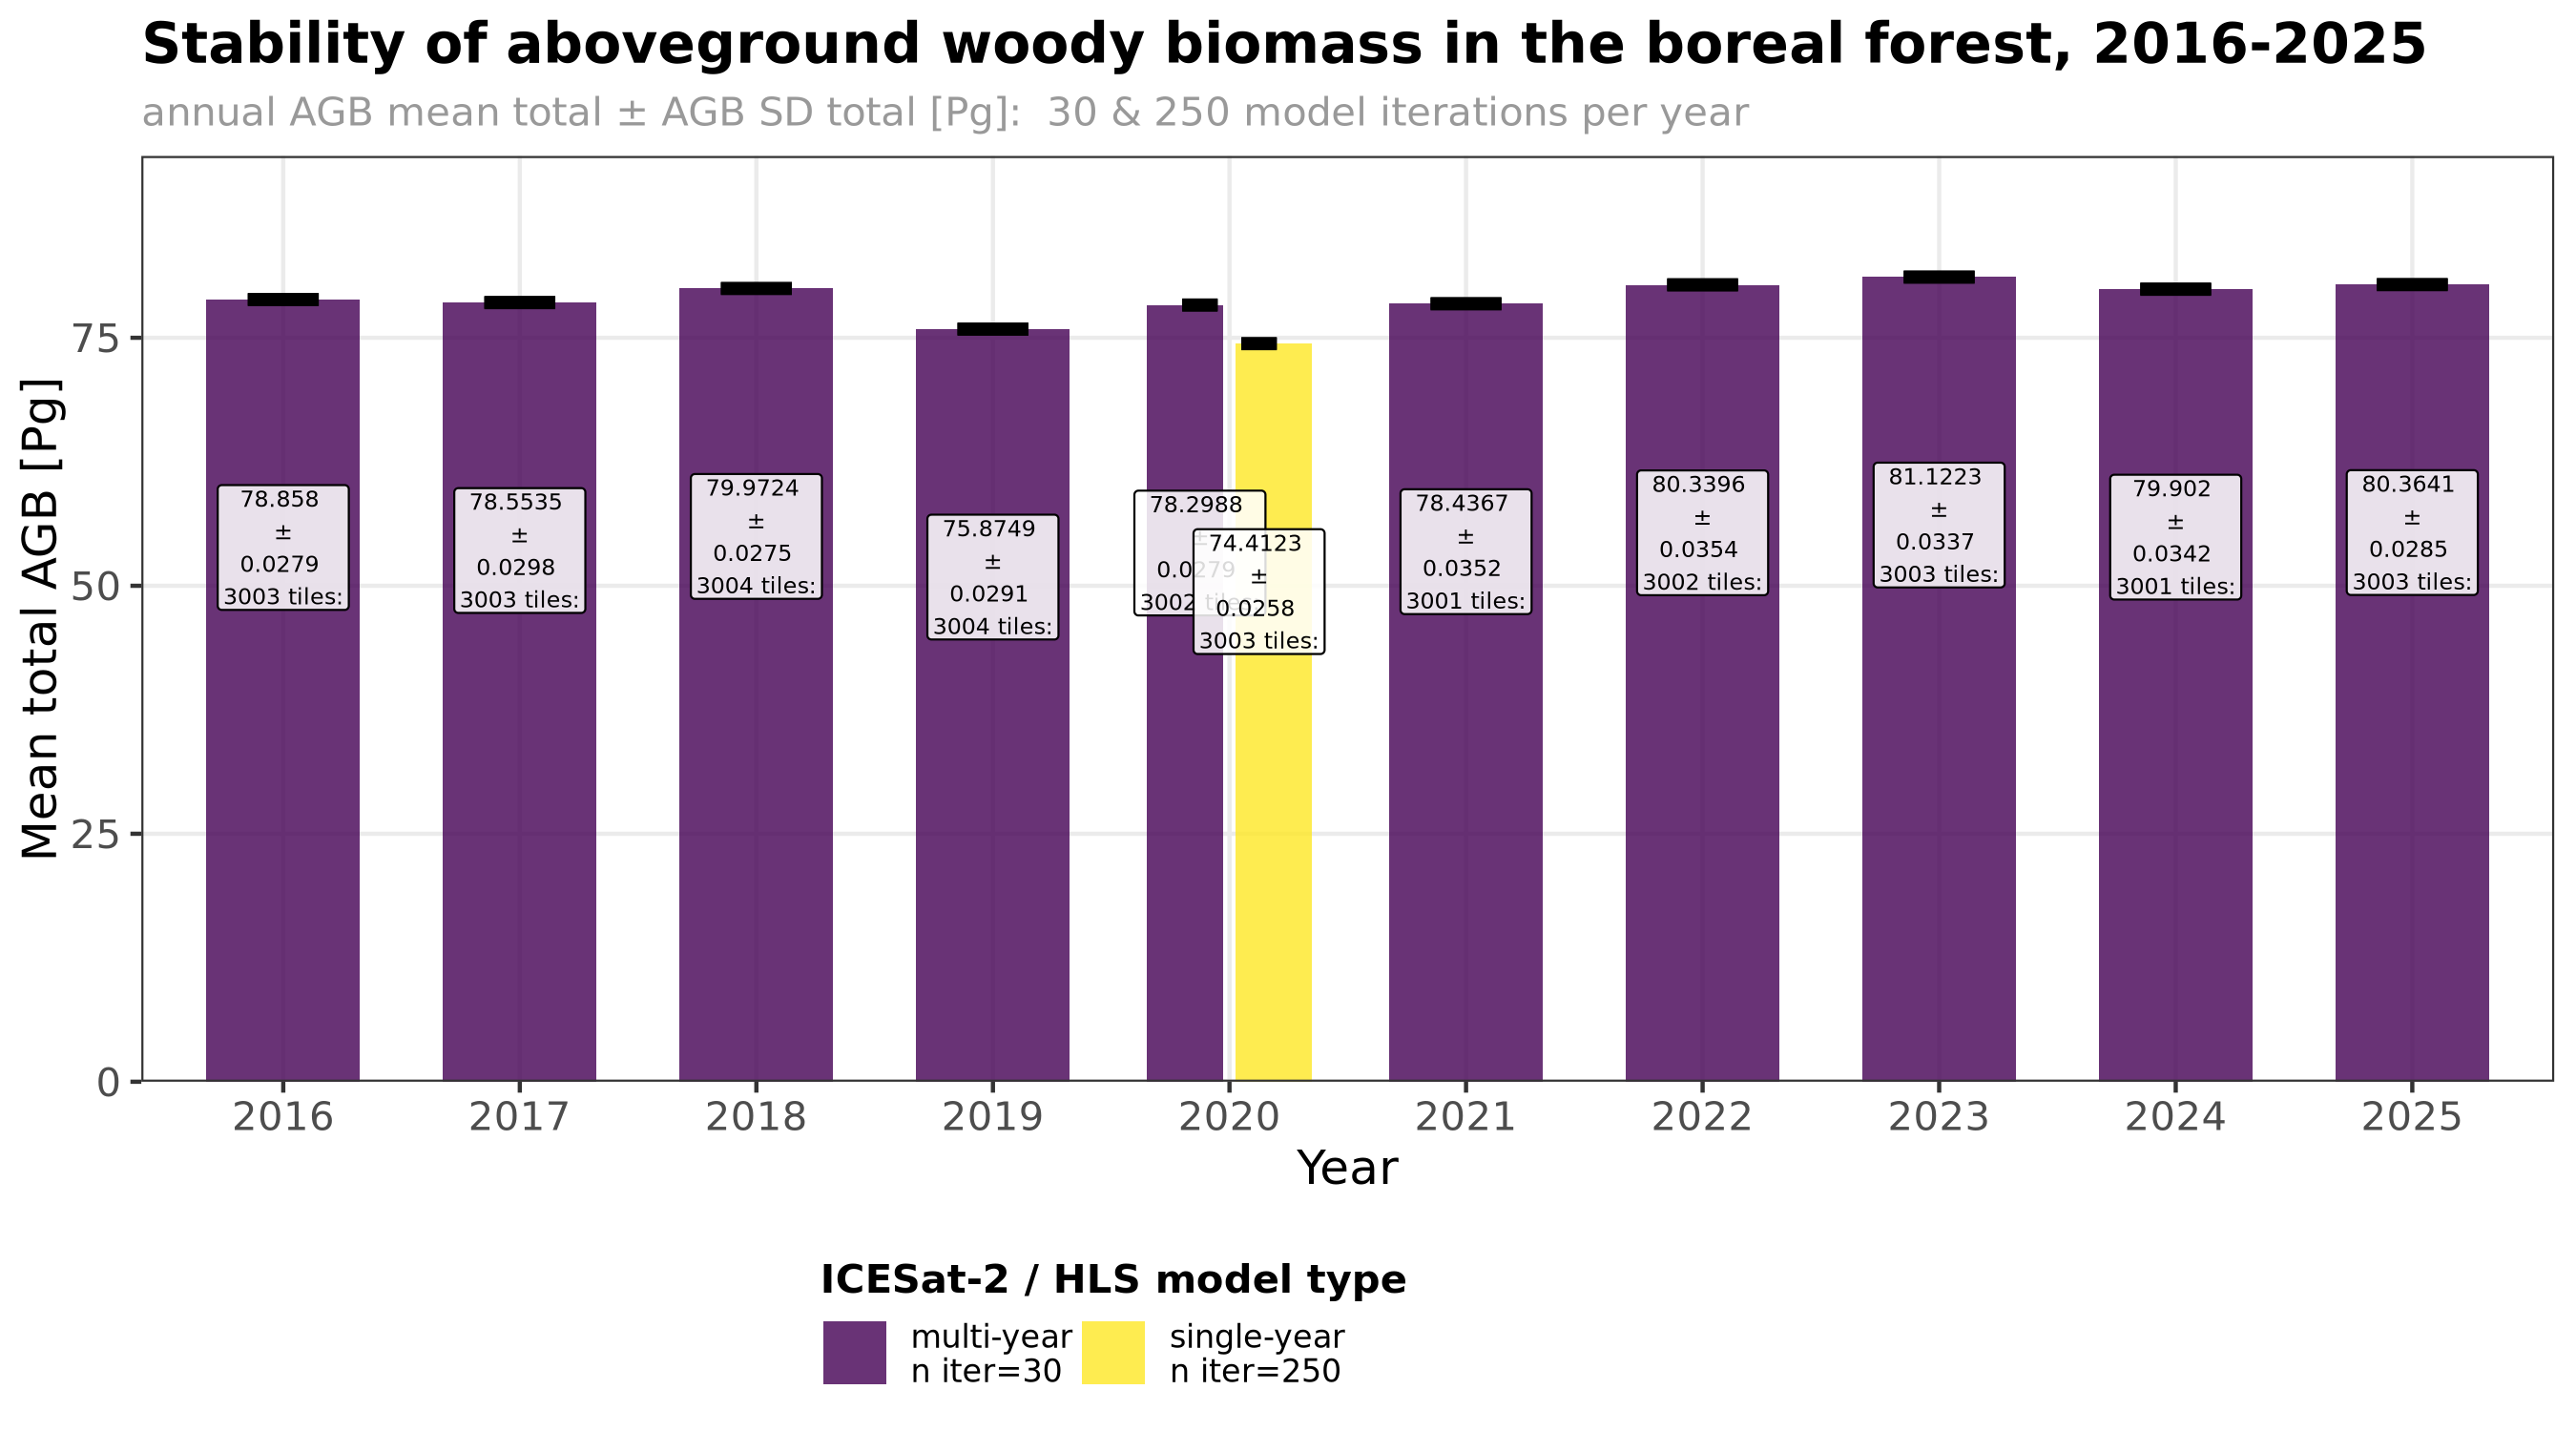
4. DPS trends calc demo'd in `compute_trends.ipynb` - do this for 2016-2025
5. CACC code
    + `code/maap_tools/notebooks/carbon_accumulation_meta_smry.ipynb`
    + 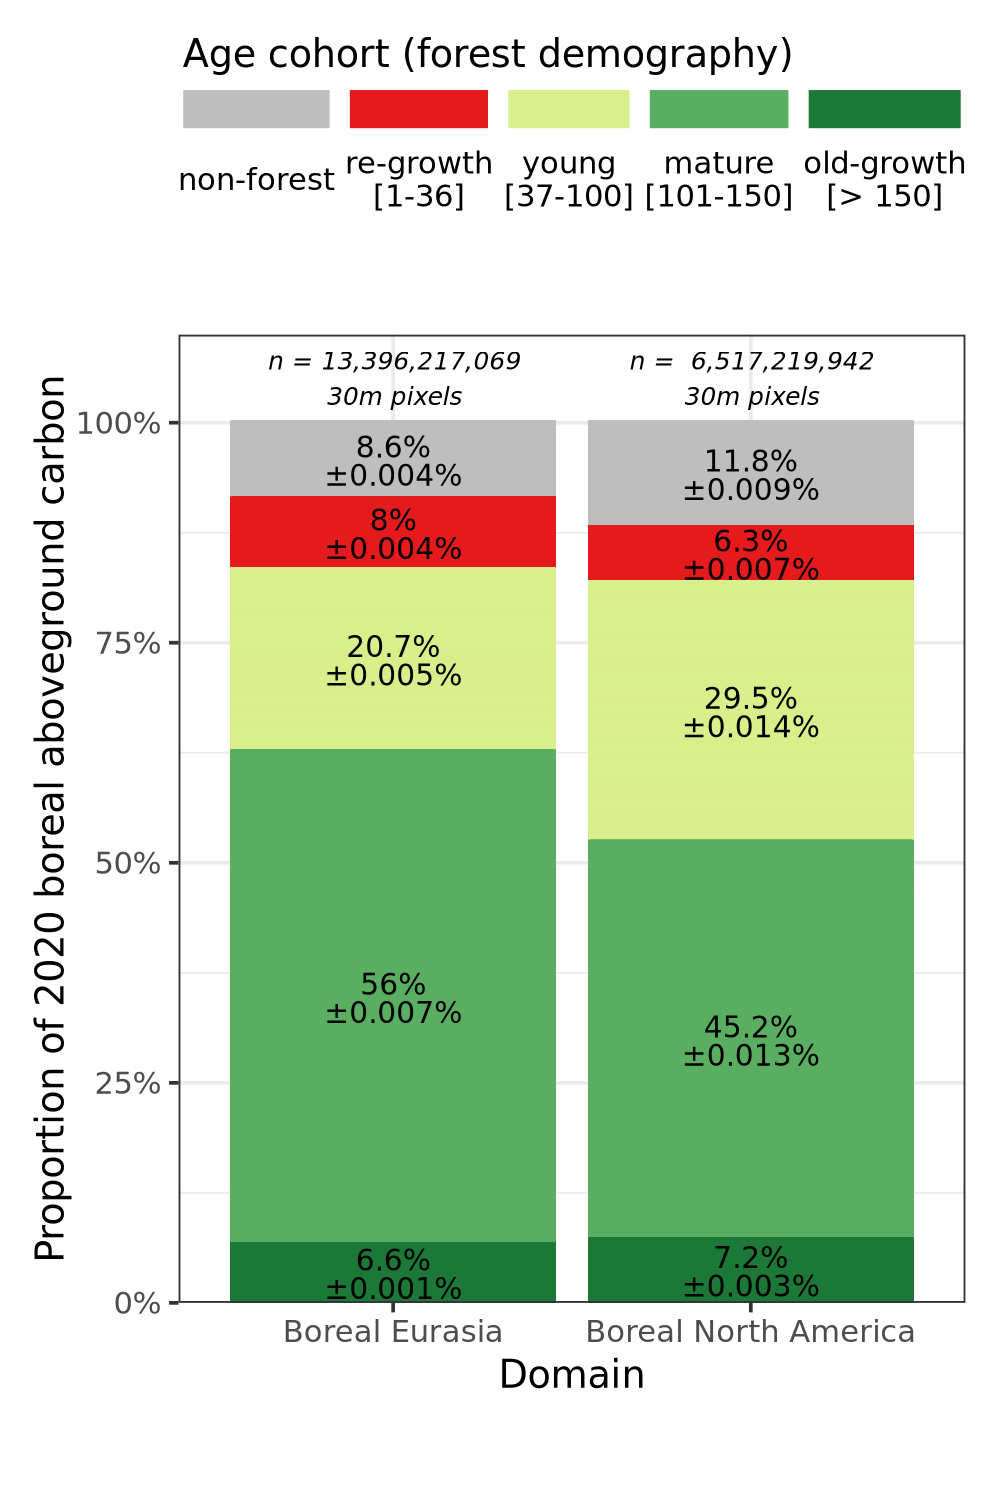
    + add summary of AGB per Age Cohort  
      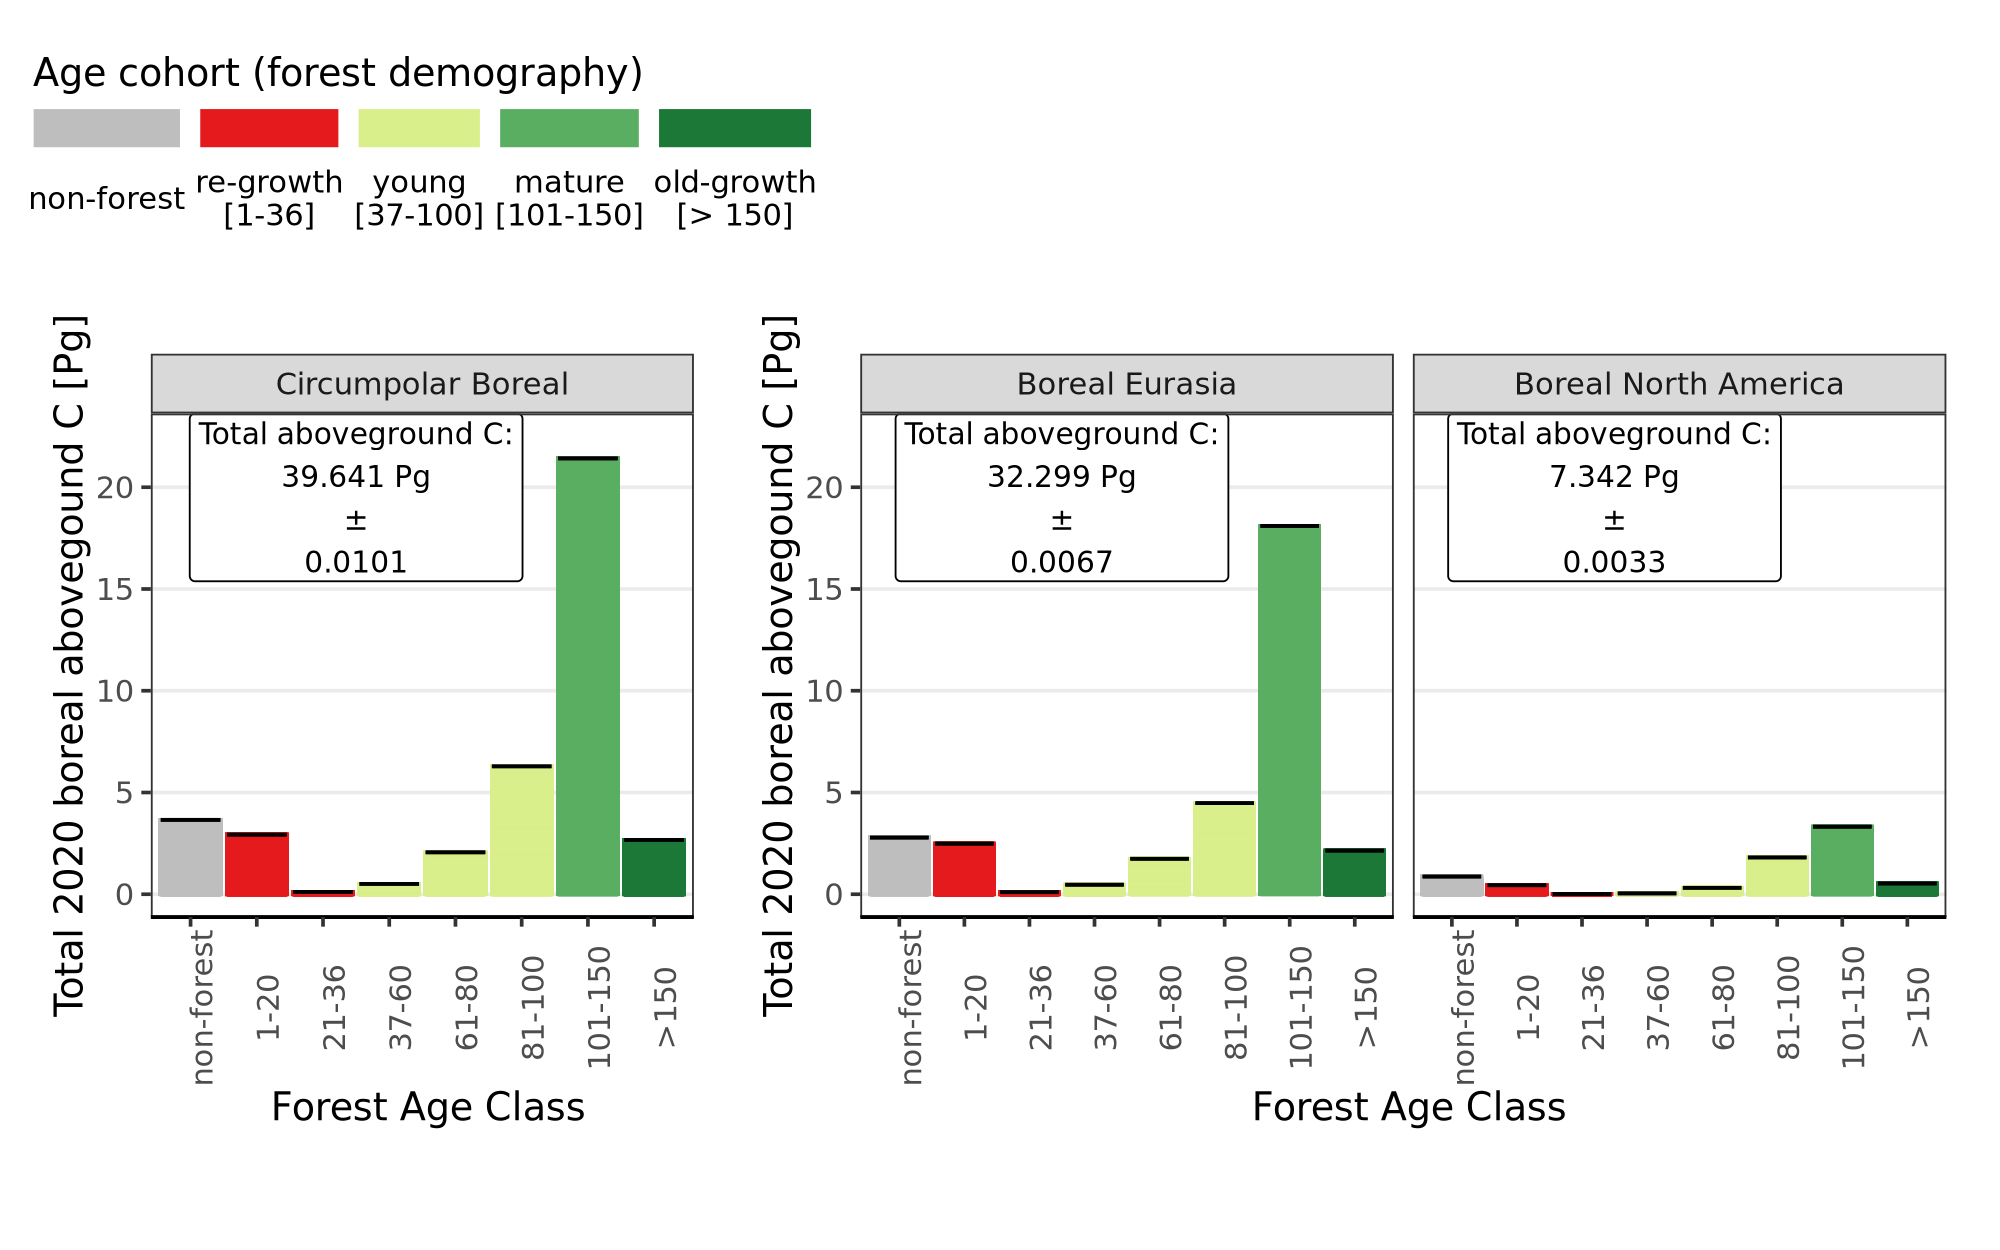
7. re-run 2020 C accumulation:
    + on `v3.1/AGB_H30_2020/full_run_niter30_multiyear_atl08v6`
    + make sure to commit bug-fix that accomodates different array shapes (3001,3001) and re-reg alg
    + check if any other summary adjustments are needed to compute uncertainty for age_classes and/or ecoregions?
8. bring new 2020 C accum together with 2016/2020-2024 AGBD trends?

#  Results from zonal stats  (just ~1000 landscapes in this test)
`code/icesat2_boreal/notebooks/zonal_stats_hybas.ipynb`

In [1]:
#library(ggalluvial) # for sankey diagram

In [37]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(RColorBrewer)
library(scales)
library(sf)

In [38]:
# Use the colors from your Python cmap - ordered by Kendall class sequence
trend_colors <- c(
  "strong_increase" = "#0000CC",    # Classes 1,2 - dark blue (first in Kendall order)
  "moderate_increase" = "#8080FF",  # Classes 3,4 - light blue 
  "stable" = "#CCCCCC",             # Classes 5,6 - gray
  "moderate_decline" = "#FF8080",   # Classes 7,8 - light red
  "strong_decline" = "#CC0000"      # Classes 9,10 - dark red (last in Kendall order)
)

# Define the desired order for age classes
age_class_order <- c("non-forest", "young", "maturing", "mature", "old-growth")

# Define the desired order for trend classes (following Kendall class order)
trend_class_order <- c("strong_increase", "moderate_increase", "stable", "moderate_decline", "strong_decline")

In [39]:
# Create labels for the legend (keeping the order)
trend_labels <- c(
  "strong_increase" = "Increase\n(strong)",
  "moderate_increase" = "Increase\n(moderate)", 
  "stable" = "Stable",
  "moderate_decline" = "Decline\n(moderate",
  "strong_decline" = "Decline\n(strong)"
)

age_labels <- c(
  "non-forest" = "Non-Forest",
  "young" = "Young Forest",
  "maturing" = "Maturing Forest", 
  "mature" = "Mature Forest",
  "old-growth" = "Old Growth Forest"
)

In [40]:
library(fs)

### Local results

In [41]:
# # local output testing
# INDIR = '/projects/my-public-bucket/local_output/zonal_stats_landscapes/hybas_test_subset_00250'
# data_polygon = read.csv(path(INDIR, '/results_polygon_summary.csv'))

### DPS results

#### read in results processing in batches of n=30 landscapes - so each output dir has n landscapes

In [42]:
# Set up parallel processing
library(parallel)

# Define the reading function
read_csv_safely <- function(file) {
  result <- tryCatch({
    df <- read.csv(file, stringsAsFactors = FALSE)
    df$source_file <- basename(file)  # Add source file information
    return(df)
  }, error = function(e) {
    warning(paste("Error reading file:", file, "-", e$message))
    return(NULL)
  })
  return(result)
}

# Define the safe GPKG reading function
read_gpkg_safely <- function(file, layer = NULL, quiet = TRUE) {
  result <- tryCatch({
    # Check if file exists
    if (!file.exists(file)) {
      warning(paste("File does not exist:", file))
      return(NULL)
    }
    
    # Read the GPKG file
    if (is.null(layer)) {
      # Read first layer if no layer specified
      df <- st_read(file, quiet = quiet)
    } else {
      # Read specific layer
      df <- st_read(file, layer = layer, quiet = quiet)
    }
    
    # Add source file information
    df$source_file <- basename(file)
    
    return(df)
  }, error = function(e) {
    warning(paste("Error reading GPKG file:", file, "-", e$message))
    return(NULL)
  })
  return(result)
}

### Get output from zonal_stats_landscapes

#### we output a number of CSV files from `zonal_stats`

`biomass_results_polygon_biomass_change_long_format.csv` is most useful:
polygon_id, age_class, trend_class, value_type, biomass_mean_pg, biomass_std_pg, change_percent, prob_increase

In [43]:
IDENTIFIER = 'agb_trends_2020_2025_TEST02'
IDENTIFIER = 'agb_trends_2020_2025'
INDIR = paste0('/projects/my-private-bucket/dps_output/run_zonal_stats_landscapes/zonal_stats_landscapes_v1/',IDENTIFIER)
TARGET_CSV_FN = 'biomass_results_polygon_biomass_change_long_format.csv'

csv_files <- list.files(path = INDIR,
                        pattern = paste0(TARGET_CSV_FN,"$"), 
                        recursive = TRUE, full.names = TRUE)

# Replace "polygon" with "age_class" in each element
csv_files_results_age_class <- lapply(csv_files, function(x) gsub("polygon", "age_class", x))
# Replace "polygon" with "trend_age" in each element
csv_files_results_trend_age <- lapply(csv_files, function(x) gsub("polygon", "trend_age", x))
length(csv_files)

[1] 8

### Polygon age x trend classes with monte carlo biomass totals for 2020 and 2025, and change

In [16]:
gpkg_files <- unlist(lapply(csv_files, function(x) gsub(TARGET_CSV_FN, "biomass_results.gpkg", x)))

In [44]:
num_cores <- detectCores() - 1  # Leave one core free
cl <- makeCluster(num_cores)

# Export necessary functions and variables to the cluster
clusterExport(cl, c("csv_files", "gpkg_files", "read_csv_safely", "read_gpkg_safely"))

# Load required packages on each core
invisible(clusterEvalQ(cl, {
  library(utils)
  library(sf)  # Required for read_gpkg_safely
}))

# Read CSV files in parallel
system.time({
  results_list <- parLapply(cl, csv_files, read_csv_safely)
})

# Read GPKG files in parallel
system.time({
  results_gdf_list <- parLapply(cl, gpkg_files, read_gpkg_safely)
})

# Close the cluster
stopCluster(cl)

# Remove NULL results (failed reads)
results_list <- results_list[!sapply(results_list, is.null)]
gdf_list <- results_gdf_list[!sapply(results_gdf_list, is.null)]

# Debug: Check what we got
cat("Found", length(results_list), "valid CSV files\n")
cat("Found", length(gdf_list), "valid GPKG files\n")

# Check if gdf_list is empty and debug
if (length(gdf_list) == 0) {
  cat("Debugging GPKG files:\n")
  cat("Number of GPKG files to read:", length(gpkg_files), "\n")
  cat("First few GPKG file paths:\n")
  print(head(gpkg_files))
  
  # Test reading one file manually
  if (length(gpkg_files) > 0) {
    cat("Testing manual read of first GPKG file:\n")
    test_read <- read_gpkg_safely(gpkg_files[1])
    print(class(test_read))
    if (!is.null(test_read)) {
      cat("Manual read successful - issue is with parallel processing\n")
    } else {
      cat("Manual read also failed - issue with file paths or function\n")
    }
  }
}

   user  system elapsed 
  0.015   0.008   0.579 

   user  system elapsed 
  0.004   0.000   0.045 

Found 8 valid CSV files
Found 0 valid GPKG files
Debugging GPKG files:
Number of GPKG files to read: 3 
First few GPKG file paths:
[1] "/projects/my-private-bucket/dps_output/run_zonal_stats_landscapes/zonal_stats_landscapes_v1/agb_trends_2020_2025/2026/01/07/14/43/17/590405/biomass_results.gpkg"
[2] "/projects/my-private-bucket/dps_output/run_zonal_stats_landscapes/zonal_stats_landscapes_v1/agb_trends_2020_2025/2026/01/07/16/01/11/734415/biomass_results.gpkg"
[3] "/projects/my-private-bucket/dps_output/run_zonal_stats_landscapes/zonal_stats_landscapes_v1/agb_trends_2020_2025/2026/01/07/17/28/41/306532/biomass_results.gpkg"
Testing manual read of first GPKG file:


Warning message in doTryCatch(return(expr), name, parentenv, handler):
“File does not exist: /projects/my-private-bucket/dps_output/run_zonal_stats_landscapes/zonal_stats_landscapes_v1/agb_trends_2020_2025/2026/01/07/14/43/17/590405/biomass_results.gpkg”


[1] "NULL"
Manual read also failed - issue with file paths or function


## Combine all data: results df and gpkg

In [45]:
# Combine data frames (only if we have data)
if (length(results_list) > 0) {
  results <- do.call(rbind, results_list)
  cat("Combined", length(results_list), "CSV files into a data frame with", 
      nrow(results), "rows and", ncol(results), "columns\n")
}

Combined 8 CSV files into a data frame with 18000 rows and 9 columns


### Get landscapes from processed polygon IDs

In [46]:
POLYGON_ID_LIST = results$polygon_id

In [47]:
# This will be  problematic for gpkg files that have some missing cols
# if (length(gdf_list) > 0) {
#   results_sf <- do.call(rbind, gdf_list[1:21])
#   cat("Combined", length(gdf_list), "GPKG files into a spatial data frame with", 
#       nrow(results_sf), "rows and", ncol(results_sf), "columns\n")
# } else {
#   cat("No valid GPKG files found or read\n")
# }

In [49]:
#ncol(gdf_list[[3]])

In [50]:
results

polygon_id,age_class,trend_class,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,source_file
<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
2080440820,non-forest,strong_decline,agb_2020,8.344375e-08,6.312354e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,strong_decline,agb_2025,3.338501e-08,1.301221e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,strong_decline,agb_2020_to_agb_2025,-5.005874e-08,6.451387e-09,-59.990996,0.000,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,moderate_decline,agb_2020,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,moderate_decline,agb_2025,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,moderate_decline,agb_2020_to_agb_2025,0.000000e+00,0.000000e+00,NA,0.000,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,stable,agb_2020,1.195121e-05,2.500672e-08,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,stable,agb_2025,1.284498e-05,1.785480e-08,NA,NA,biomass_results_polygon_biomass_change_long_format.csv
2080440820,non-forest,stable,agb_2020_to_agb_2025,8.937654e-07,3.033235e-08,7.478451,1.000,biomass_results_polygon_biomass_change_long_format.csv


In [32]:
# # Read the spatial data
# ecoregions_sf <- st_read("/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg")

# # Perform spatial intersection
# # This creates a new sf object with geometries and attributes from both layers
# intersected <- st_intersection(results_sf, ecoregions_sf)

# # If you want to keep only the intersection results and convert to regular dataframe
# intersection_df <- intersected %>%
#     st_drop_geometry()  # Remove geometry column to get regular dataframe

# # Join the ecoregion info to your plot_results using polygon_id
# plot_results_with_ecoregions <- plot_results %>%
#     left_join(intersection_df, by = "polygon_id")

In [51]:
source('/projects/code/maap_tools/notebooks/boreal_smry_functions.r')

In [53]:
LOOKUP_RDS_FN = "/projects/my-public-bucket/databank/hydrobasins/hybas_lake_hilat40N_75N_lev08_v1c_ecoregion_lookup.rds"

In [54]:
lookup <- readRDS(LOOKUP_RDS_FN)

In [55]:
if(FALSE){
    # Step 1: Create the lookup table (do this once)
    lookup <- create_basin_ecoregion_lookup(
      hydrobasins_path = "/projects/my-public-bucket/databank/hydrobasins/hybas_lake_hilat40N_75N_lev08_v1c.gpkg",
      ecoregions_path = "/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg"
    )
    
    # Optional: Save the lookup table for future use
    saveRDS(lookup, LOOK_RDS_FN)
    }

In [56]:
# Step 2: Add ecoregion info to your dataframe
# Assuming you have a dataframe called 'my_data' with a column 'polygon_id'
results <- add_ecoregion_info(results, lookup, basin_id_col = "polygon_id") %>%
            mutate(biome_name = factor(
                ifelse(
                  as.character(BIOME) %in% names(ecoregion_biome_dict),
                  ecoregion_biome_dict[as.character(BIOME)],
                  paste0("Biome ", BIOME)  # Fallback for unknown codes
            )))

Added ecoregion info to 18000 rows

Basins with ecoregion match: 18000



In [57]:
results

polygon_id,age_class,trend_class,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,source_file,ECO_NAME,BIOME,REALM,biome_name
<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<fct>
2080440820,non-forest,strong_decline,agb_2020,8.344375e-08,6.312354e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,strong_decline,agb_2025,3.338501e-08,1.301221e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,strong_decline,agb_2020_to_agb_2025,-5.005874e-08,6.451387e-09,-59.990996,0.000,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,moderate_decline,agb_2020,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,moderate_decline,agb_2025,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,moderate_decline,agb_2020_to_agb_2025,0.000000e+00,0.000000e+00,NA,0.000,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,stable,agb_2020,1.195121e-05,2.500672e-08,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,stable,agb_2025,1.284498e-05,1.785480e-08,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"
2080440820,non-forest,stable,agb_2020_to_agb_2025,8.937654e-07,3.033235e-08,7.478451,1.000,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands"


### TODO: these 'results' need to get count (n_pixels?) info joined from another results csv

`biomass_results_trend_age_summary.csv` --> polygon_id, trenc_class, age_class, n_pixels

In [58]:
# # Prepare data for plotting

plot_results <- results %>%
    #drop_na() %>%
    # Apply factor ordering
    mutate(
    AGB_year = value_type,
    age_class = factor(age_class, levels = age_class_order),
    trend_class = droplevels(factor(trend_class, levels = trend_class_order))
      ) %>%
    mutate(AGB_year = gsub("2020_to_2025$", "Change", gsub("agb_","", AGB_year)))
    #   # Remove any age classes that aren't in our data
    #   #filter(!is.na(age_class))  %>%
    #   mutate(
    #     cumulative_count = cumsum(`2020_count`),
    #     text_position = cumulative_count - proportion/2,  # Center text in each segment
    #     # Only show text for segments with >2% of total
    #     proportion_label = ifelse(proportion >= 0.002, 
    #                              paste0(round(proportion * 100, 2), "%"), 
    #                              "")
    #   ) %>%
    #     #mutate(total_decline_prop = strong_decline_prop + moderate_decline_prop) %>%
    #     arrange(desc(proportion)) 

In [65]:
smry_total_Pg = plot_results %>% 
        group_by(REALM, biome_name, age_class, trend_class, AGB_year) %>%
        summarise(
            Pg_mean = sum(biomass_mean_pg, na.rm = TRUE),
            Pg_std = sum(biomass_std_pg, na.rm = TRUE)
            ) 
    
head(smry_total_Pg)

`summarise()` has grouped output by 'REALM', 'biome_name', 'age_class',
'trend_class'. You can override using the `.groups` argument.


REALM,biome_name,age_class,trend_class,AGB_year,Pg_mean,Pg_std
<chr>,<fct>,<fct>,<fct>,<chr>,<dbl>,<dbl>
PA,Deserts & Xeric Shrublands,non-forest,strong_increase,2020,3.283043e-04,2.681016e-07
PA,Deserts & Xeric Shrublands,non-forest,strong_increase,2025,3.032387e-04,4.179717e-07
PA,Deserts & Xeric Shrublands,non-forest,strong_increase,Change,-2.506559e-05,5.101337e-07
PA,Deserts & Xeric Shrublands,non-forest,moderate_increase,2020,0.000000e+00,0.000000e+00
PA,Deserts & Xeric Shrublands,non-forest,moderate_increase,2025,0.000000e+00,0.000000e+00
PA,Deserts & Xeric Shrublands,non-forest,moderate_increase,Change,0.000000e+00,0.000000e+00


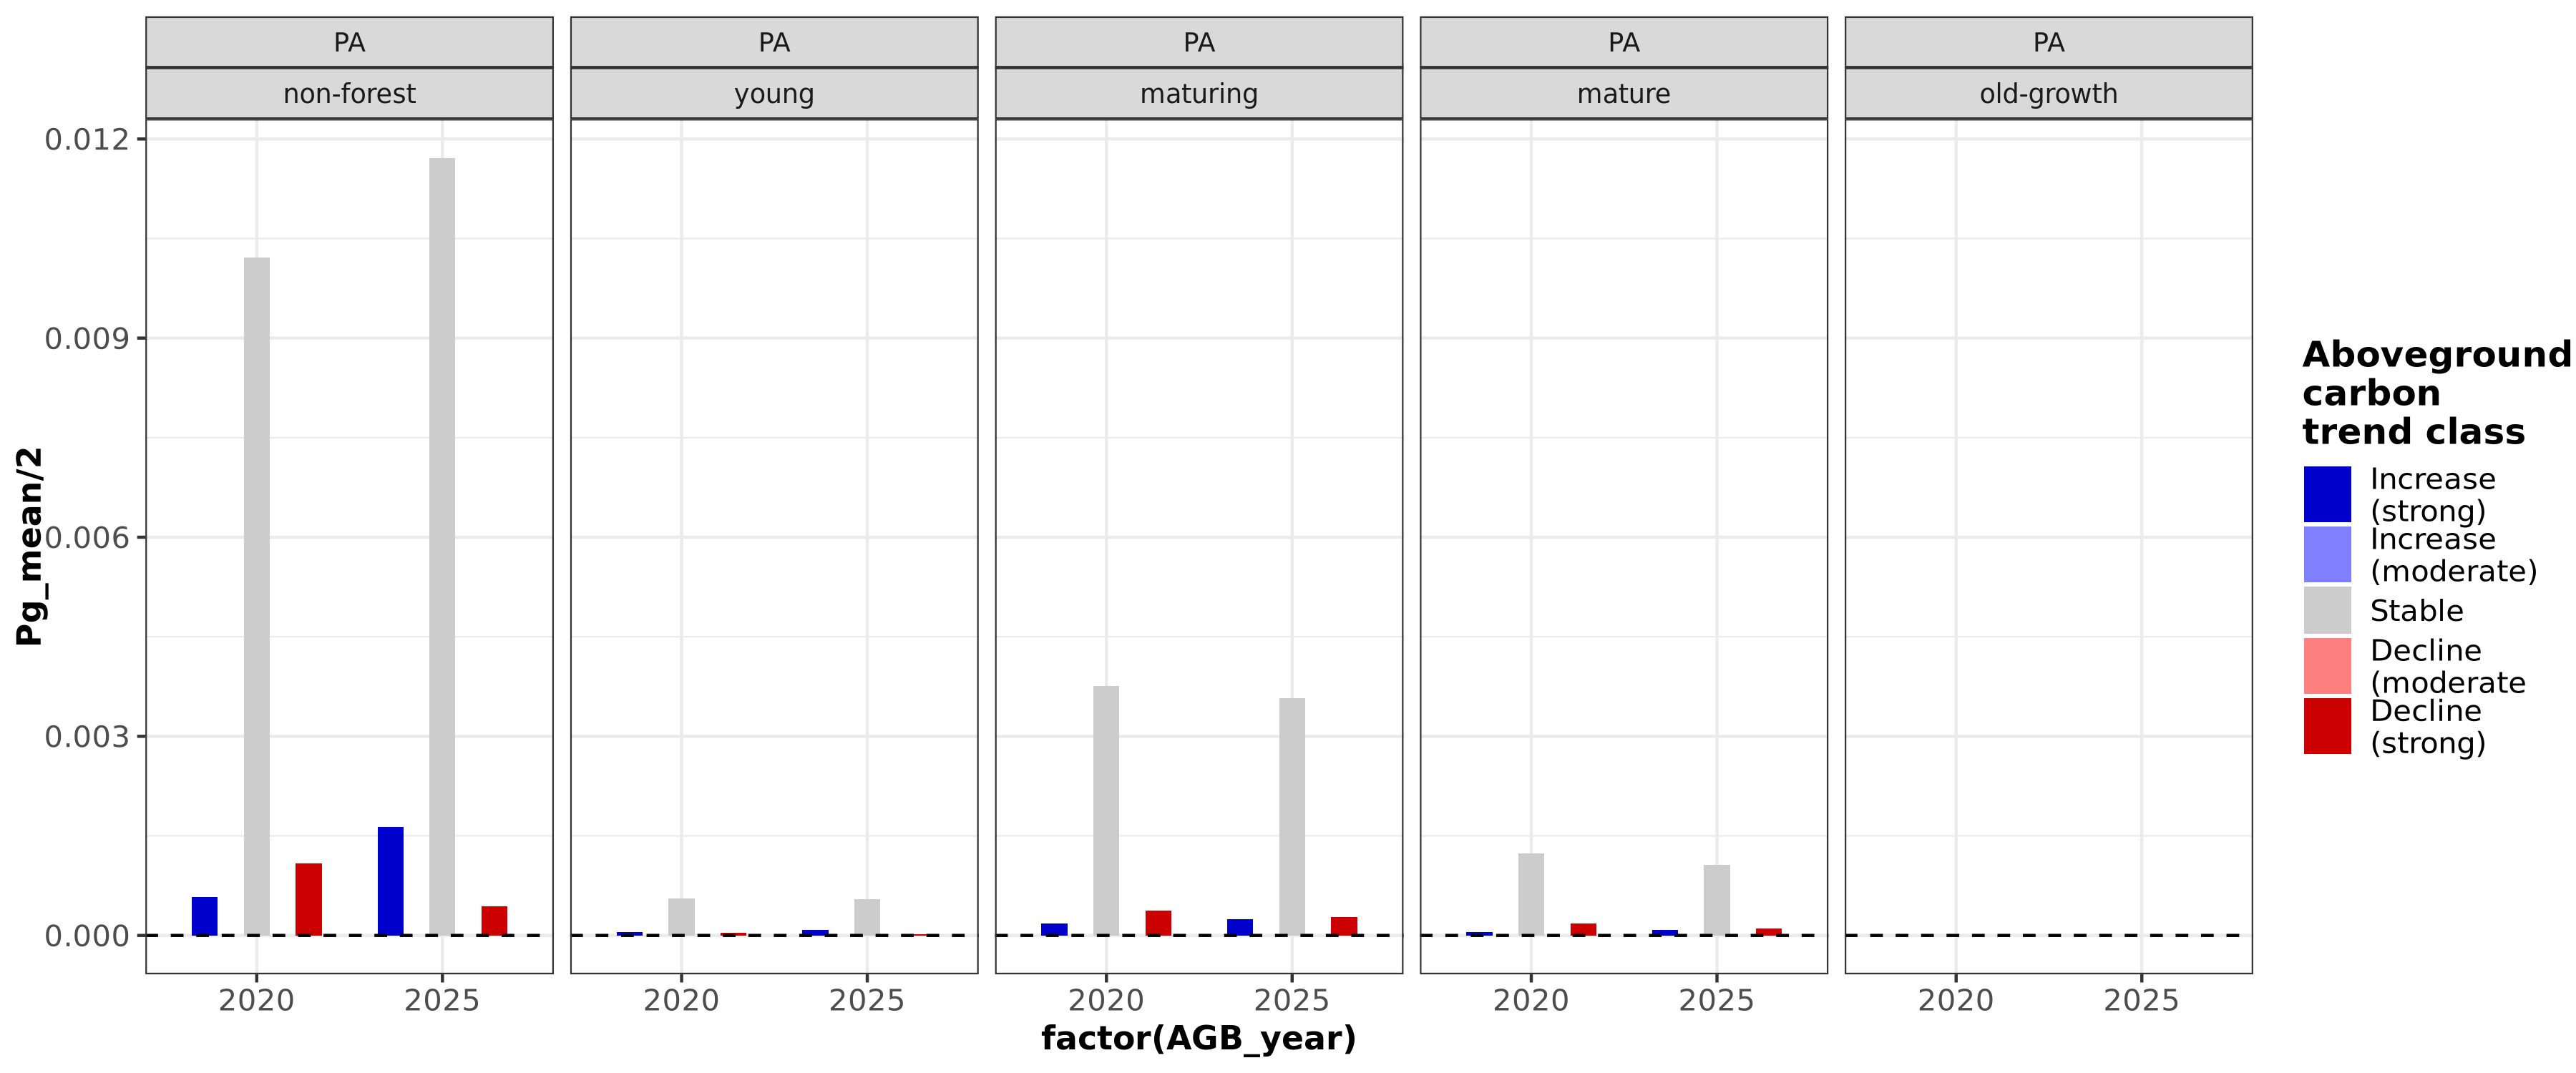

In [66]:
options(repr.plot.width = 12, repr.plot.height = 5, repr.plot.res = 300)

# # If you want to check what age classes are actually in your data:
# print("Age classes found in data:")
# print(unique(data_trend_age$age_class))

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(
    smry_total_Pg %>% filter(AGB_year != 'Change')
       , aes(x = factor(AGB_year) , y = `Pg_mean`/2, fill = trend_class
                                #, group=interaction(factor(AGB_year))
                               )
      ) +   # <---- NOTE: DIviding by 2 to take AGB to C
    geom_bar(stat = "identity", position = "dodge", width = 0.7) +
    geom_hline(yintercept=0, linetype='dashed') + 
    scale_fill_manual(values = trend_colors,
                    name = "Aboveground \ncarbon\ntrend class ",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +
    
    scale_y_continuous(
      #labels = percent_format(), 
    #name = paste0("% of pixels across all landscapes (n=",length(unique(plot_data$polygon_id)),")")
    ) +
    labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #x = "Year"
    ) +
    theme_bw() +
    theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
      #axis.text.x = element_text(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    #panel.grid.minor = element_blank(),
    #panel.grid.major.y = element_blank()
    ) +
    facet_wrap(REALM~age_class, ncol=5, scales='free_x')

In [32]:
# colnames(plot_data_trend_age)
# This table used to have these cols
# 'polygon_id''age_class''age_range''n_pixels''trend_class''2020_count''AGB_year''Pg''proportion''cumulative_count''text_position''proportion_label'

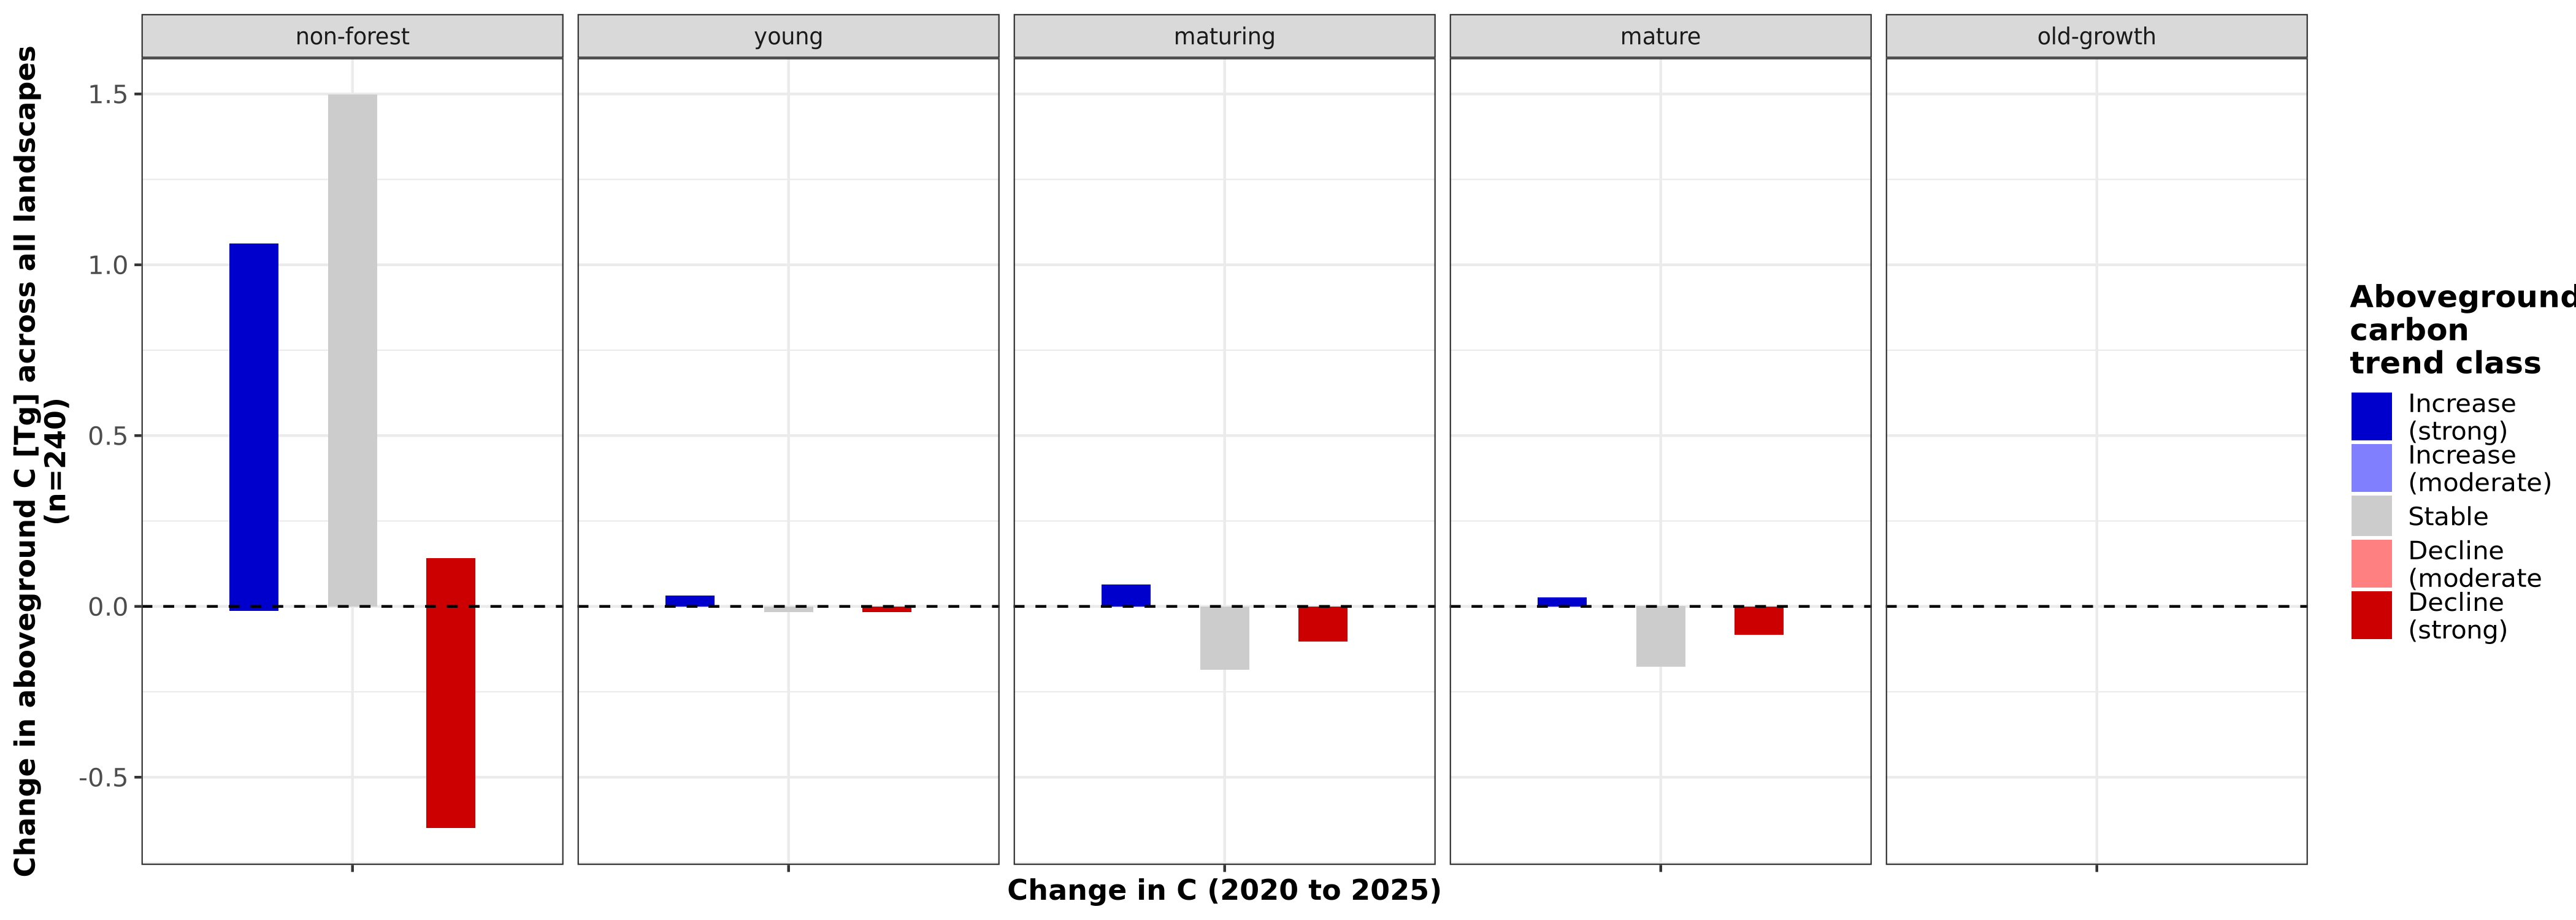

In [67]:
options(repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 300)

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(
    smry_total_Pg %>% filter(AGB_year == 'Change')
       , aes(x = factor(AGB_year) , y = `Pg_mean`/2 * 1000, fill = trend_class
                                #, group=interaction(factor(AGB_year))
                               )
      ) +   # <---- NOTE: DIviding by 2 to take AGB to C
    geom_bar(stat = "identity", position = "dodge", width = 0.7) +
    geom_hline(yintercept=0, linetype='dashed') + 
    scale_fill_manual(values = trend_colors,
                    name = "Aboveground\ncarbon\ntrend class ",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +
    
    scale_y_continuous(
      #labels = percent_format(), 
    name = paste0("Change in aboveground C [Tg] across all landscapes\n(n=",length(unique(results$polygon_id)),")")
    ) +
    labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       x = "Change in C (2020 to 2025)"
    ) +
    theme_bw() +
    theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    #panel.grid.minor = element_blank(),
    #panel.grid.major.y = element_blank()
    ) +
    facet_wrap(~age_class, ncol=5, scales='free_x')

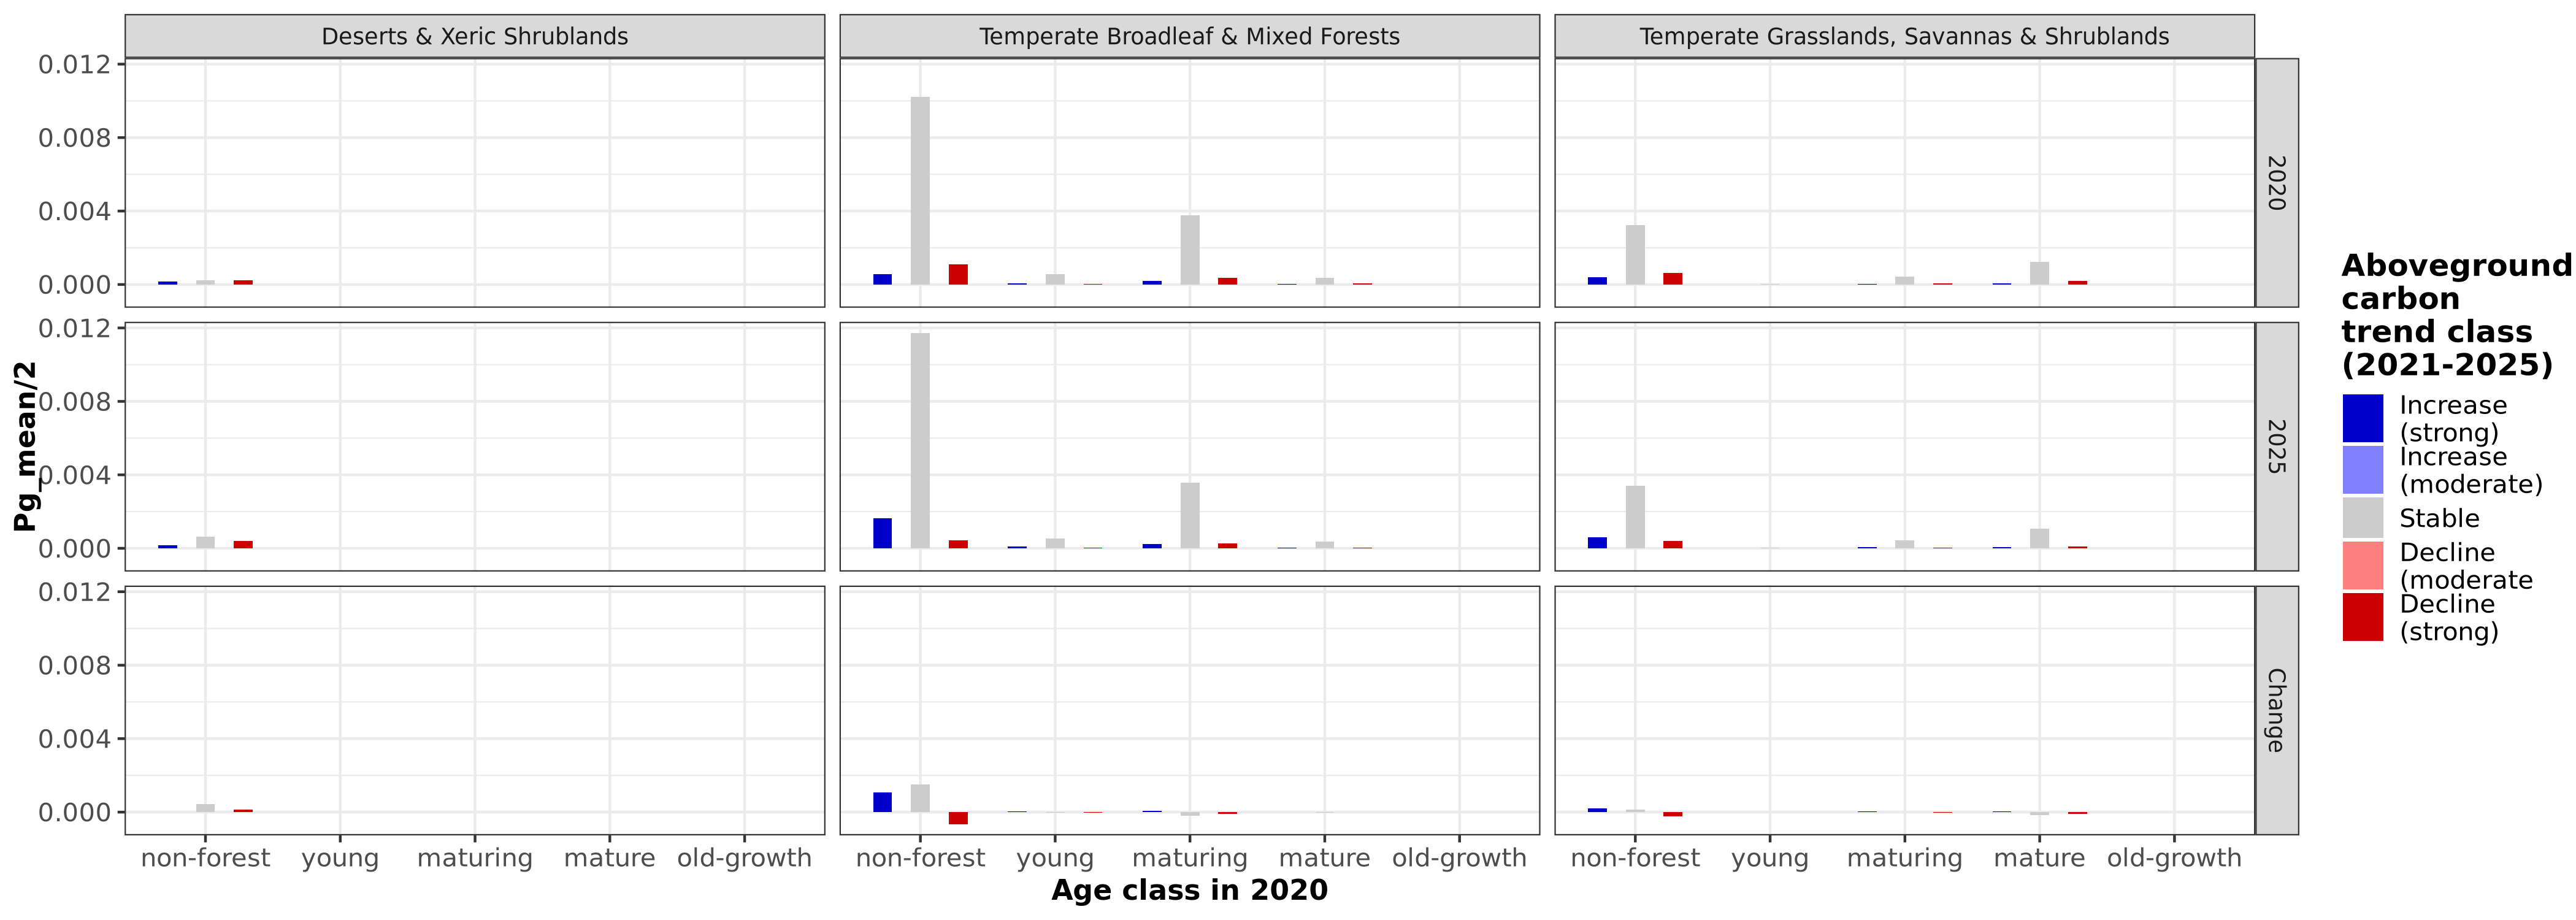

In [69]:
options(repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 300)

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(smry_total_Pg, aes(x = factor(age_class), y = `Pg_mean`/2, fill = trend_class)) +   # <---- NOTE: DIviding by 2 to take AGB to C
  geom_bar(stat = "identity", position = "dodge", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground \ncarbon\ntrend class\n(2021-2025) ",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
      #labels = percent_format(), 
    #name = paste0("% of pixels across all landscapes (n=",length(unique(plot_data$polygon_id)),")")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x = 'Age class in 2020'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
      #axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    #panel.grid.minor = element_blank(),
    #panel.grid.major.y = element_blank()
  ) + 
facet_grid(AGB_year~biome_name)



In [70]:
head(plot_results)

,polygon_id,age_class,trend_class,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,source_file,ECO_NAME,BIOME,REALM,biome_name,AGB_year
,<dbl>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<fct>,<chr>
1,2080440820,non-forest,strong_decline,agb_2020,8.344375e-08,6.312354e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",2020
2,2080440820,non-forest,strong_decline,agb_2025,3.338501e-08,1.301221e-09,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",2025
3,2080440820,non-forest,strong_decline,agb_2020_to_agb_2025,-5.005874e-08,6.451387e-09,-59.991,0,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",Change
4,2080440820,non-forest,moderate_decline,agb_2020,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",2020
5,2080440820,non-forest,moderate_decline,agb_2025,0.000000e+00,0.000000e+00,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",2025
6,2080440820,non-forest,moderate_decline,agb_2020_to_agb_2025,0.000000e+00,0.000000e+00,NA,0,biomass_results_polygon_biomass_change_long_format.csv,Kazakh steppe,8,PA,"Temperate Grasslands, Savannas & Shrublands",Change


**This plot shows the carbon (Pg) totals for landscapes in 2020 and 2025 by 2020 age class. **

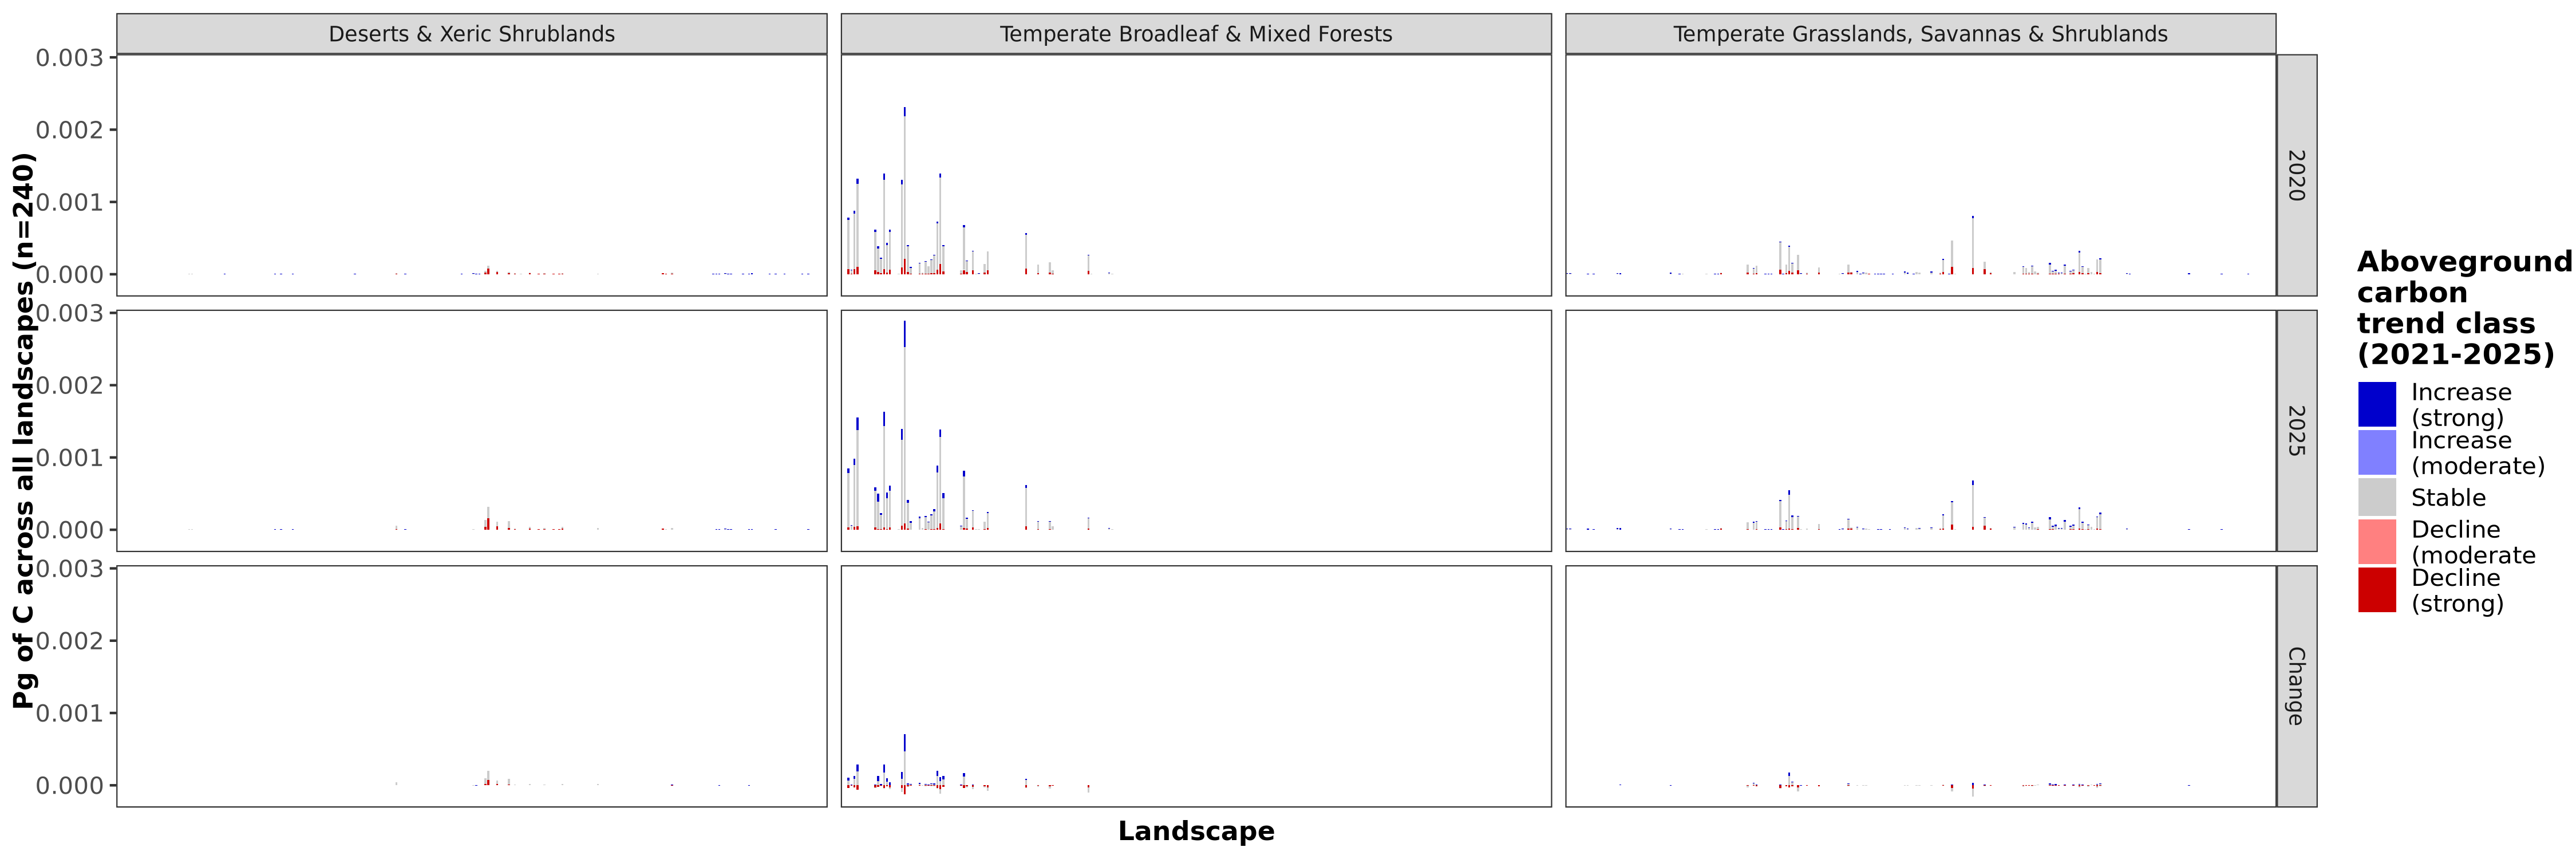

In [71]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

# # If you want to check what age classes are actually in your data:
# print("Age classes found in data:")
# print(unique(data$age_class))

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(plot_results 
       , aes(x = factor(polygon_id), y = biomass_mean_pg/2, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground \ncarbon\ntrend class\n(2021-2025)",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    #labels = percent_format(), 
    name = paste0("Pg of C across all landscapes (n=",length(unique(results$polygon_id)),")")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
facet_grid(AGB_year~biome_name)

In [17]:
tail(plot_results)

,polygon_id,age_class,trend_class,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,source_file,AGB_year
,<dbl>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
224995,3080669300,old-growth,moderate_increase,agb_2020,0,0,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,2020
224996,3080669300,old-growth,moderate_increase,agb_2025,0,0,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,2025
224997,3080669300,old-growth,moderate_increase,agb_2020_to_agb_2025,0,0,NA,0,biomass_results_polygon_biomass_change_long_format.csv,Change
224998,3080669300,old-growth,strong_increase,agb_2020,0,0,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,2020
224999,3080669300,old-growth,strong_increase,agb_2025,0,0,NA,NA,biomass_results_polygon_biomass_change_long_format.csv,2025
225000,3080669300,old-growth,strong_increase,agb_2020_to_agb_2025,0,0,NA,0,biomass_results_polygon_biomass_change_long_format.csv,Change


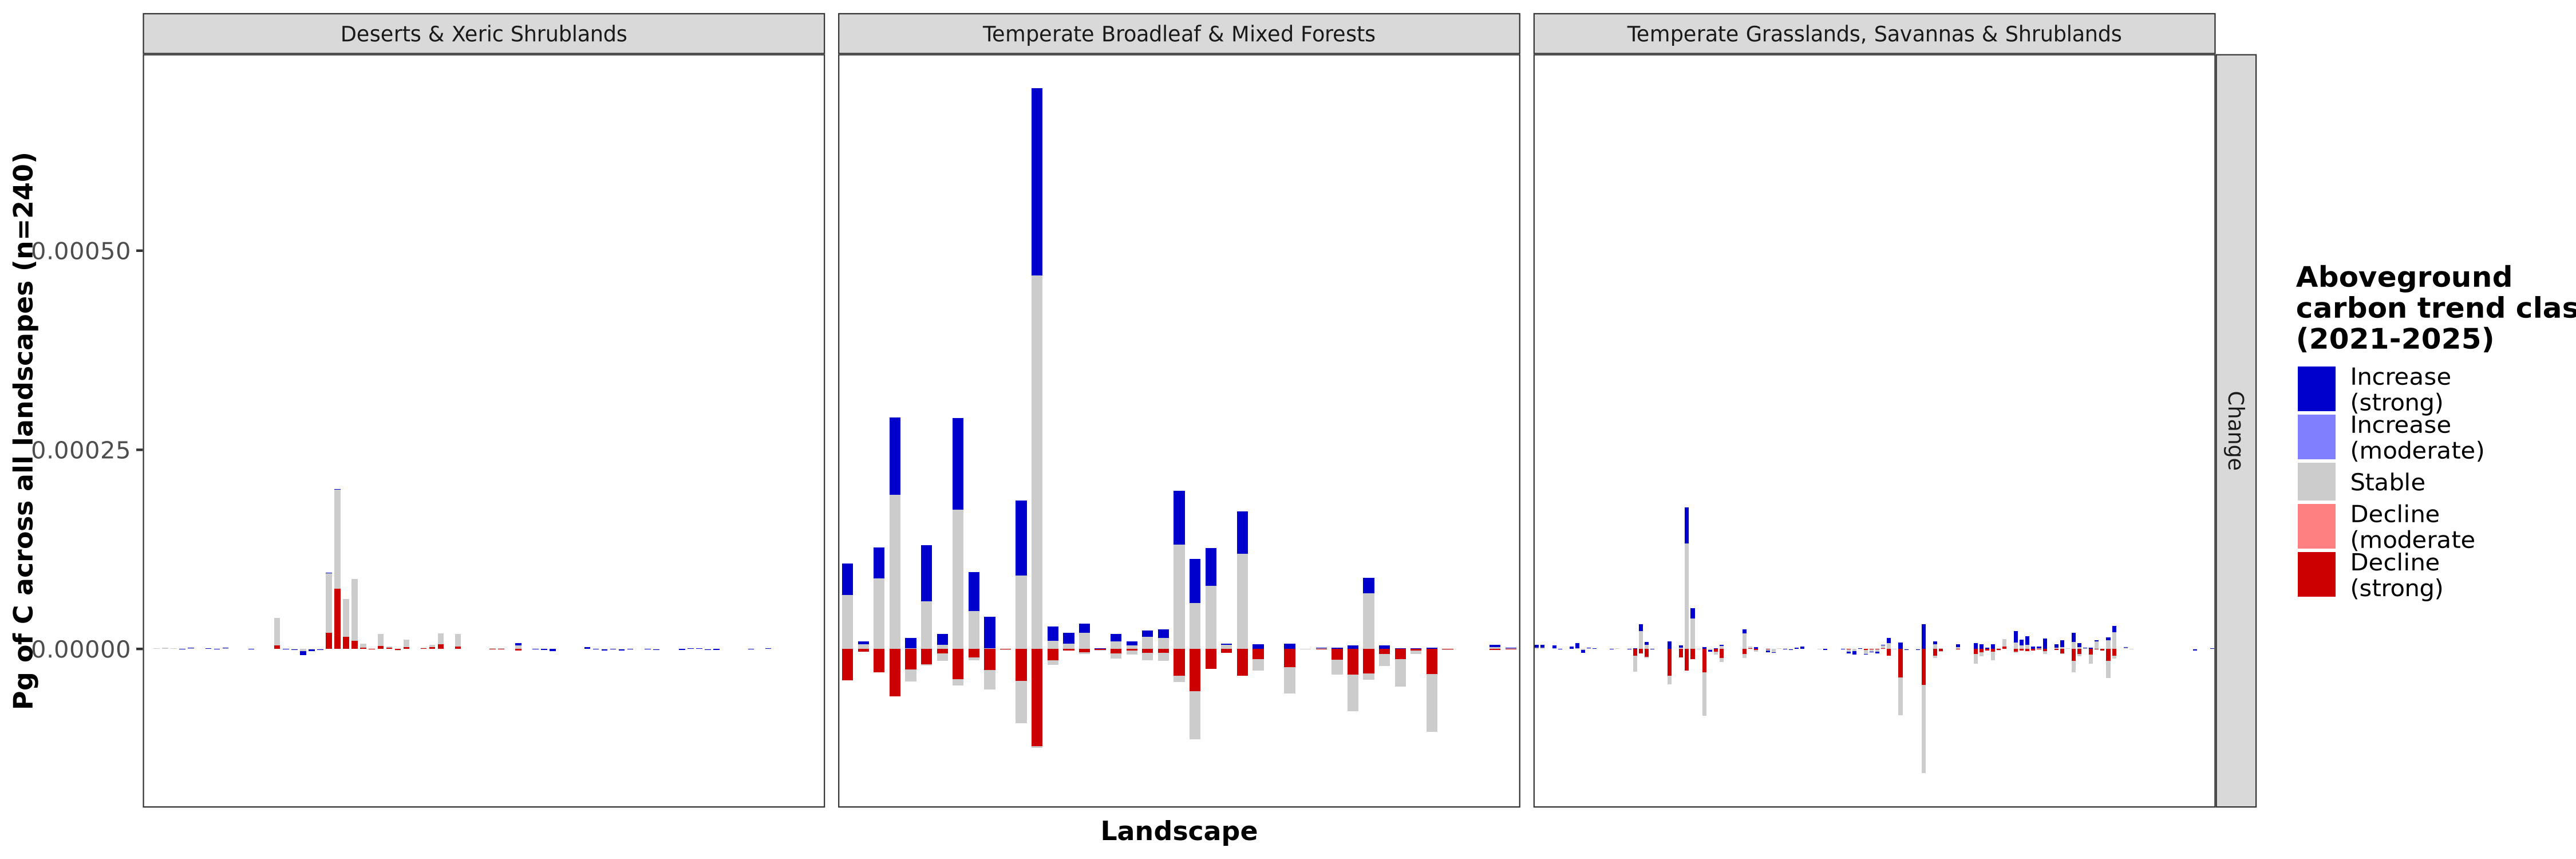

In [75]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

# # If you want to check what age classes are actually in your data:
# print("Age classes found in data:")
# print(unique(data$age_class))

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(plot_results %>% filter(AGB_year == 'Change')
       , aes(x = factor(polygon_id), y = biomass_mean_pg/2, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground\ncarbon trend class\n(2021-2025)",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    #labels = percent_format(), 
    name = paste0("Pg of C across all landscapes (n=",length(unique(results$polygon_id)),")")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
facet_grid(AGB_year~biome_name, scales='free_x')

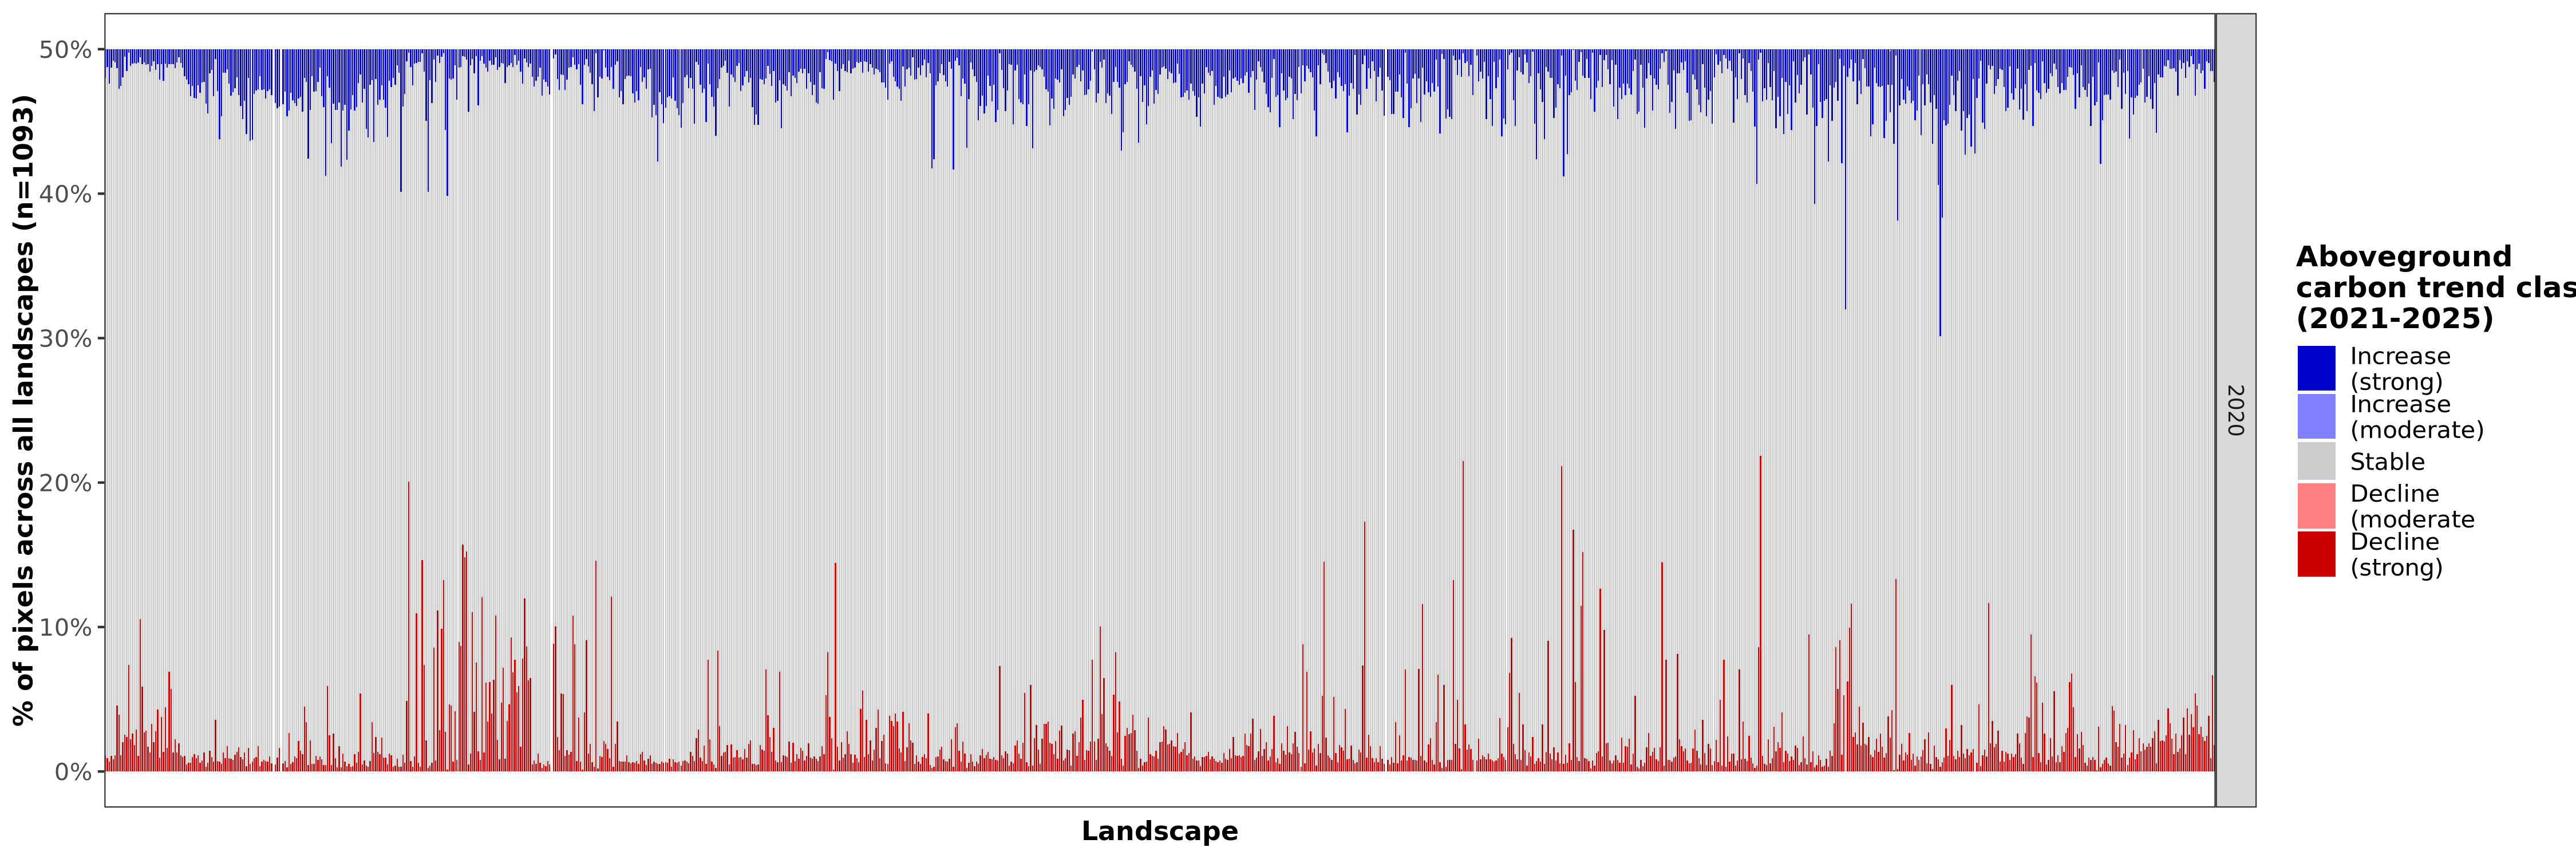

In [154]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

# # If you want to check what age classes are actually in your data:
# print("Age classes found in data:")
# print(unique(data$age_class))

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(plot_data_trend_age %>% filter(AGB_year == 2020) # only 1 year needed for this - both AGB_year will have only 1 trend per polygon (obs)
       , aes(x = factor(polygon_id), y = proportion, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground\ncarbon trend class\n(2021-2025)",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    labels = percent_format(), 
    name = paste0("% of pixels across all landscapes (n=",length(unique(plot_data_trend_age$polygon_id)),")")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
facet_grid(AGB_year~.)



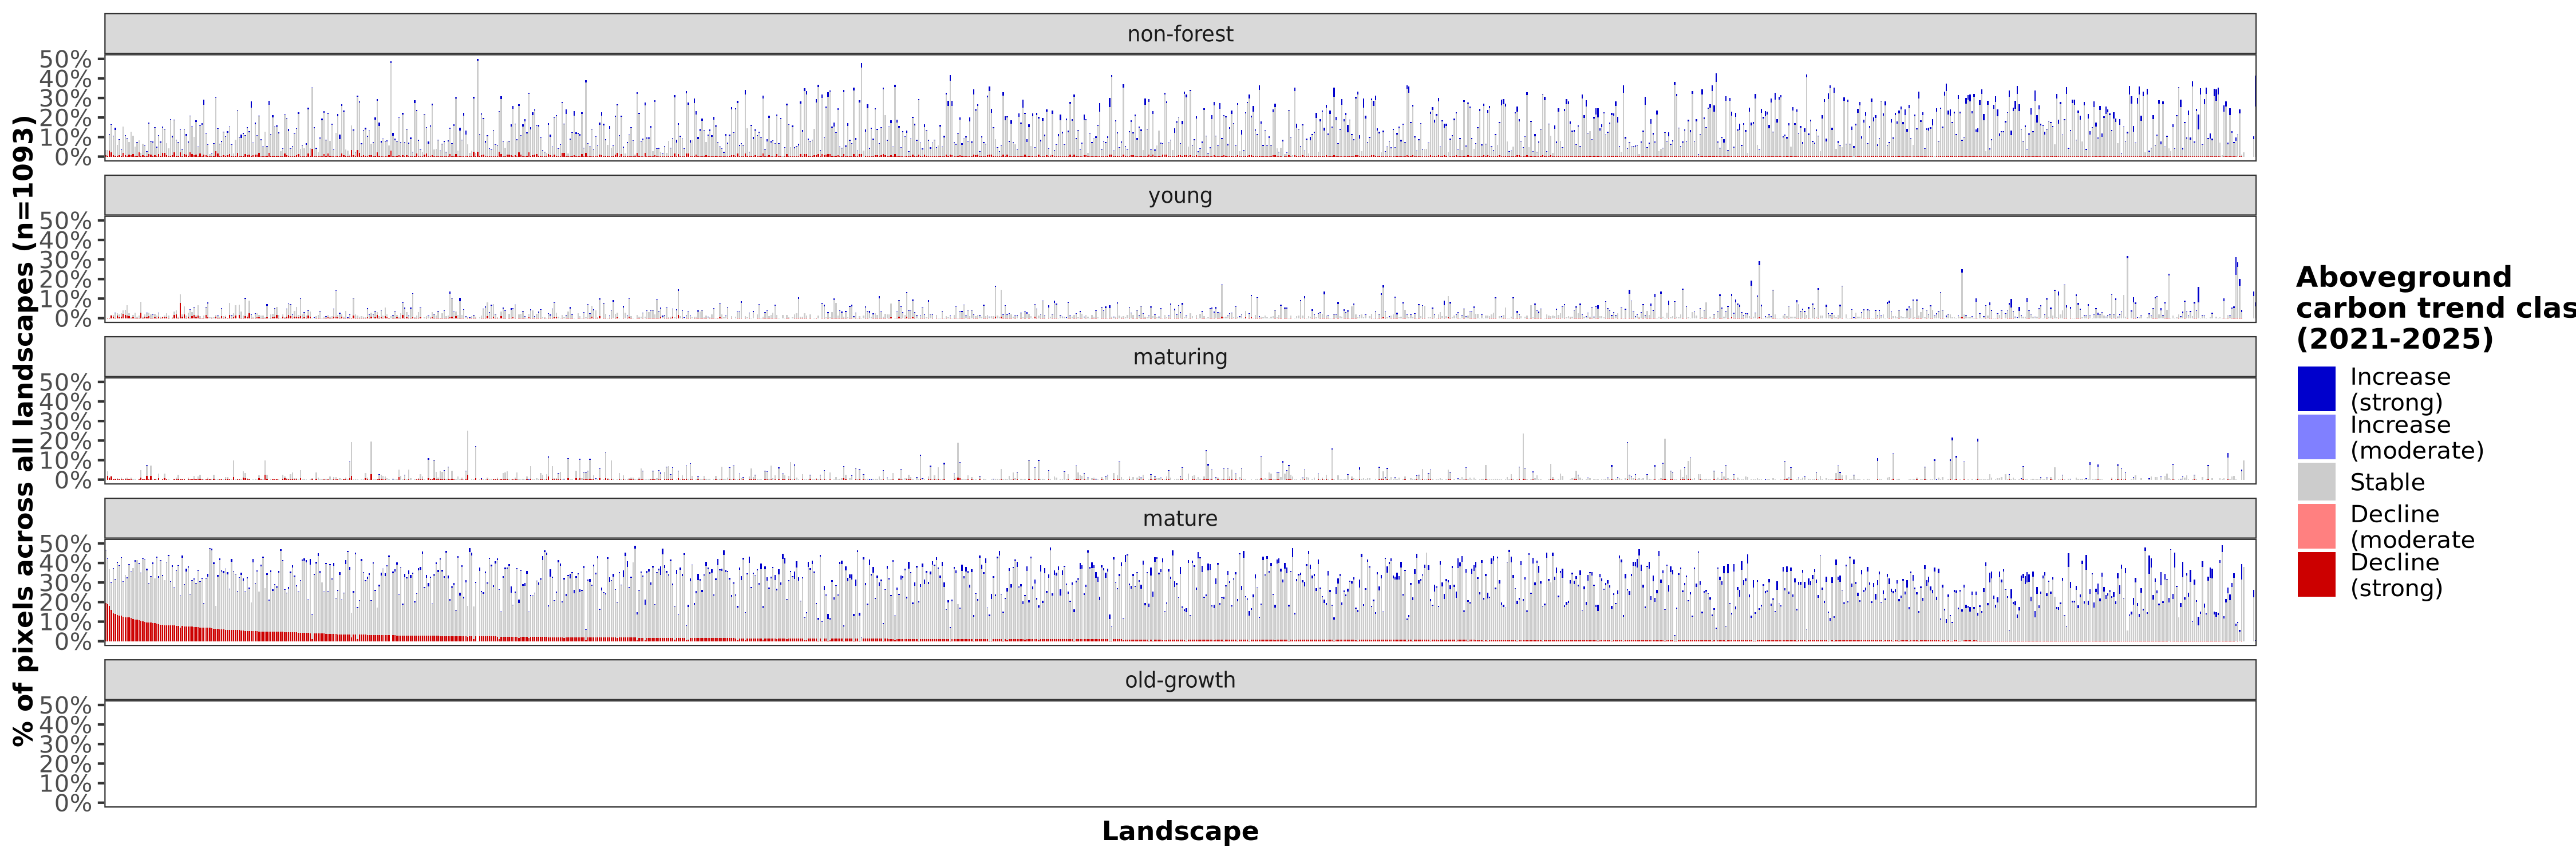

In [157]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

# # If you want to check what age classes are actually in your data:
# print("Age classes found in data:")
# print(unique(data$age_class))

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

# First, create the ordering based on strong_decrease proportions
polygon_order <- plot_data_trend_age %>%
  filter(trend_class == "strong_decline", AGB_year == '2025') %>%
  arrange(desc(proportion), trend_class) %>%
  pull(polygon_id)

ggplot(plot_data_trend_age  %>% filter(AGB_year == 2020) # only 1 year needed for this - both AGB_year will have only 1 trend per polygon (obs)
       , aes(x = factor(polygon_id, levels = unique(polygon_order)), y = proportion, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground\ncarbon trend class\n(2021-2025)",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    labels = percent_format(), 
    name = paste0("% of pixels across all landscapes (n=",length(unique(plot_data_trend_age$polygon_id)),")")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
facet_wrap(~age_class, ncol=1)

